# MCMC-PESP: Porównanie z Metodami Bazowymi

Ten notebook realizuje eksperymenty z **MATH_SPEC.md Sekcja 10.5** i **EXPERIMENTS.md Sekcja 6** ("Benchmark vs alternatywy").

### Sekcje:
1. **Random Search** — baseline minimum
2. **Simulated Annealing** — vs MCMC z tymi samymi propozycjami
3. **Parallel Tempering** — czy warto?
4. **Porównanie** — który jest najlepszy?

### Pytania badawcze:
- Czy MCMC bije random search?
- Czy MCMC bije SA przy tym samym budżecie?
- Czy PT daje przewagę nad single-chain MCMC?
- Koszt vs czas CPU — który algorytm jest najbardziej efektywny?

In [1]:
# ============================================================
# 0. KONFIGURACJA
# ============================================================

MODE = "quick"  # "quick" (~3-5 min) lub "full" (~20-30 min)

SEED = 42
BUDGET = 10000  # Cost function evaluations per method

if MODE == "quick":
    BUDGET = 5000
    N_SCENARIOS = 3
else:  # full
    BUDGET = 20000
    N_SCENARIOS = 6

METHODS = ["random", "mcmc", "sa", "pt"]

print(f"Mode: {MODE}")
print(f"Budget: {BUDGET} cost evaluations per method")
print(f"Methods: {METHODS}")
print(f"Scenarios: {N_SCENARIOS}")

Mode: quick
Budget: 5000 cost evaluations per method
Methods: ['random', 'mcmc', 'sa', 'pt']
Scenarios: 3


In [2]:
import sys
import os
import json
import time
from pathlib import Path
from dataclasses import asdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (14, 5)
matplotlib.rcParams['font.size'] = 11

# Project root
PROJECT_ROOT = Path(os.getcwd()).parent if 'notebooks' in os.getcwd() else Path(os.getcwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.io.synthetic_scenarios import SyntheticScenarioFactory
from src.experiments.analysis.diagnostic_runner import (
    run_random_search,
    run_simulated_annealing,
    run_benchmark_comparison,
)

factory = SyntheticScenarioFactory()
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\User\Zeszyt\pythonProject\mcmc_pesp


---
## 1. Random Search Baseline

**Pytanie z EXPERIMENTS.md**: Jakie jest minimum, które MCMC musi pobić?

**Co szukać**:
- Random search powinien być **najgorszy** (najwyższy koszt)
- Ale: przy dużym N (> 100k) może czasem znaleźć dobre rozwiązanie przez przypadek
- Median cost >> Best cost → większość losowych rozwiązań jest bardzo złych

In [3]:
# Test random search on hub (known optimum)
scenario_hub = factory.create('hub', difficulty='easy')
print(f"Scenario: {scenario_hub.metadata.name}")

random_result = run_random_search(
    scenario_hub,
    n_samples=BUDGET,
    seed=SEED,
)

print(f"\nRandom Search Results:")
print(f"  Samples evaluated: {random_result.n_samples}")
print(f"  Best cost: {random_result.best_cost:.2f}")
print(f"  Mean cost: {random_result.mean_cost:.2f}")
print(f"  Median cost: {random_result.median_cost:.2f}")
print(f"  Time: {random_result.wall_time_s:.2f}s")

if scenario_hub.metadata.optimal_solution:
    from src.core.schedule import Schedule
    from src.cost.transfer_cost import TransferCost
    
    optimal_schedule = Schedule(
        offsets=scenario_hub.metadata.optimal_solution,
        period=scenario_hub.network.period,
    )
    cost_fn = TransferCost(transfers=scenario_hub.transfers)
    optimal_cost = cost_fn(optimal_schedule, scenario_hub.network)
    
    gap = (random_result.best_cost - optimal_cost) / optimal_cost if optimal_cost > 0 else float('inf')
    print(f"  Optimal cost: {optimal_cost:.2f}")
    print(f"  Gap to optimum: {gap:.2%}")

Scenario: hub_easy

Random Search Results:
  Samples evaluated: 5000
  Best cost: 78.39
  Mean cost: 2022231.53
  Median cost: 4449.12
  Time: 0.21s
  Optimal cost: 0.00
  Gap to optimum: inf%


---
## 2. Simulated Annealing

**Pytanie z EXPERIMENTS.md**: Czy MCMC (PT) bije SA z tymi samymi propozycjami?

**Co szukać**:
- SA: cooling schedule powoduje eksploracją → eksploatację
- MCMC: stała temperatura → lepszy mixing ale może utknąć
- PT: best of both worlds?

In [4]:
# Test SA on hub
sa_result = run_simulated_annealing(
    scenario_hub,
    n_steps=BUDGET,
    T_init=100.0,
    T_final=0.01,
    cooling_schedule='geometric',
    seed=SEED,
)

print(f"Simulated Annealing Results:")
print(f"  Steps: {sa_result.n_steps}")
print(f"  Best cost: {sa_result.best_cost:.2f}")
print(f"  Acceptance rate: {sa_result.acceptance_rate:.3f}")
print(f"  Final temperature: {sa_result.final_temperature:.4f}")
print(f"  Time: {sa_result.wall_time_s:.2f}s")

if scenario_hub.metadata.optimal_solution:
    gap_sa = (sa_result.best_cost - optimal_cost) / optimal_cost if optimal_cost > 0 else float('inf')
    print(f"  Gap to optimum: {gap_sa:.2%}")

Simulated Annealing Results:
  Steps: 5000
  Best cost: 3.14
  Acceptance rate: 0.467
  Final temperature: 0.0100
  Time: 0.32s
  Gap to optimum: inf%


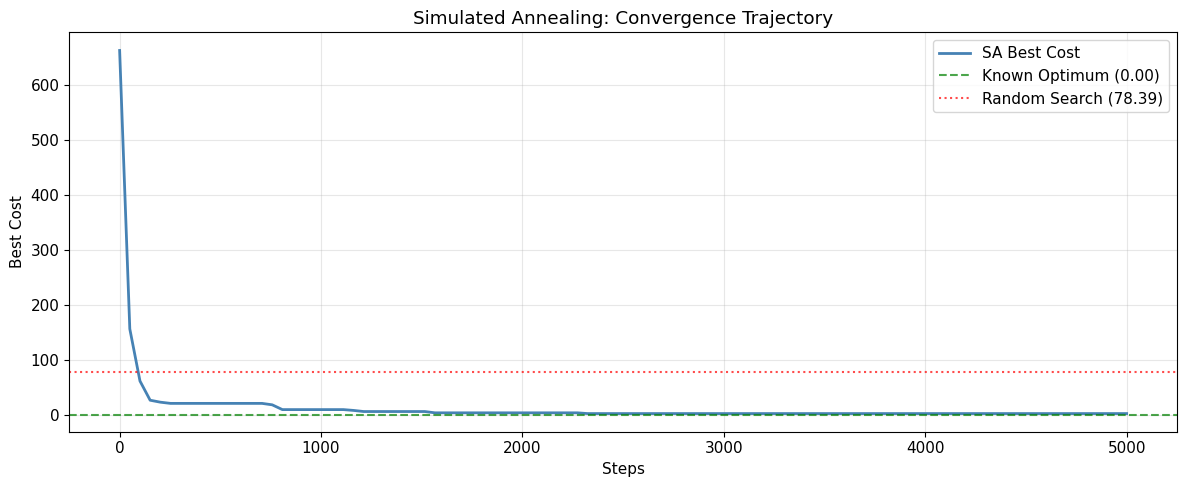

In [5]:
# Plot SA trajectory
fig, ax = plt.subplots(figsize=(12, 5))

checkpoints = np.linspace(0, sa_result.n_steps, len(sa_result.cost_trajectory))
ax.plot(checkpoints, sa_result.cost_trajectory, linewidth=2, color='steelblue', label='SA Best Cost')

if scenario_hub.metadata.optimal_solution:
    ax.axhline(optimal_cost, color='green', linestyle='--', label=f'Known Optimum ({optimal_cost:.2f})', alpha=0.7)

ax.axhline(random_result.best_cost, color='red', linestyle=':', label=f'Random Search ({random_result.best_cost:.2f})', alpha=0.7)

ax.set_xlabel('Steps')
ax.set_ylabel('Best Cost')
ax.set_title('Simulated Annealing: Convergence Trajectory')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Porównanie Wszystkich Metod

**Pytanie**: Który algorytm jest najlepszy?

**Scenariusze testowe**:
- Hub easy (znane optimum)
- Chain medium (znane optimum, long-range dependencies)
- Multi-hub mesh (realistyczny, hierarchiczny)
- Conflicting (trudny, multimodalny)

In [6]:
# Select scenarios
if MODE == "quick":
    scenario_specs = [
        ('hub', 'easy'),
        ('chain', 'easy'),
        ('multi_hub_mesh', 'easy'),
    ]
else:
    scenario_specs = [
        ('hub', 'easy'),
        ('hub', 'medium'),
        ('chain', 'easy'),
        ('chain', 'medium'),
        ('multi_hub_mesh', 'easy'),
        ('conflicting', 'easy'),
    ]

comparison_results = []

for stype, diff in scenario_specs:
    scenario = factory.create(stype, difficulty=diff)
    print(f"\nRunning benchmark: {scenario.metadata.name}...")
    
    result = run_benchmark_comparison(
        scenario,
        methods=METHODS,
        budget=BUDGET,
        seed=SEED,
    )
    comparison_results.append(result)
    
    print(f"  {' | '.join(result.methods)}")
    print(f"  {' | '.join([f'{c:8.1f}' for c in result.best_costs])} (best costs)")
    print(f"  {' | '.join([f'{t:8.2f}s' for t in result.wall_times])} (times)")


Running benchmark: hub_easy...
  Random Search | MCMC (single chain) | Simulated Annealing | Parallel Tempering (M=4)
      78.4 |      3.1 |      3.1 |      3.1 (best costs)
      0.23s |     0.44s |     0.22s |     0.55s (times)

Running benchmark: chain_easy...
  Random Search | MCMC (single chain) | Simulated Annealing | Parallel Tempering (M=4)
       0.7 |      0.7 |      0.7 |      0.7 (best costs)
      0.05s |     0.37s |     0.23s |     0.36s (times)

Running benchmark: multi_hub_mesh_easy...
  Random Search | MCMC (single chain) | Simulated Annealing | Parallel Tempering (M=4)
   23173.4 |   8961.0 |   3114.0 |   3291.6 (best costs)
      0.31s |     0.57s |     0.40s |     0.53s (times)


In [7]:
# Summary table
print("=" * 100)
print("BENCHMARK COMPARISON SUMMARY")
print("=" * 100)
print(f"\n{'Scenario':<30} {'Method':<25} {'Best Cost':>12} {'Time(s)':>10} {'Eval/s':>10}")
print("-" * 100)

for result in comparison_results:
    for i, method in enumerate(result.methods):
        evals_per_sec = result.n_evaluations[i] / result.wall_times[i] if result.wall_times[i] > 0 else 0
        print(f"{result.scenario_name if i == 0 else '':<30} {method:<25} {result.best_costs[i]:>12.2f} {result.wall_times[i]:>10.2f} {evals_per_sec:>10.0f}")
    print("-" * 100)

print("\n" + "=" * 100)

BENCHMARK COMPARISON SUMMARY

Scenario                       Method                       Best Cost    Time(s)     Eval/s
----------------------------------------------------------------------------------------------------
hub_easy                       Random Search                    78.39       0.23      22004
                               MCMC (single chain)               3.14       0.44      11363
                               Simulated Annealing               3.14       0.22      22950
                               Parallel Tempering (M=4)          3.14       0.55       9020
----------------------------------------------------------------------------------------------------
chain_easy                     Random Search                     0.70       0.05     102360
                               MCMC (single chain)               0.70       0.37      13345
                               Simulated Annealing               0.70       0.23      21615
                               P

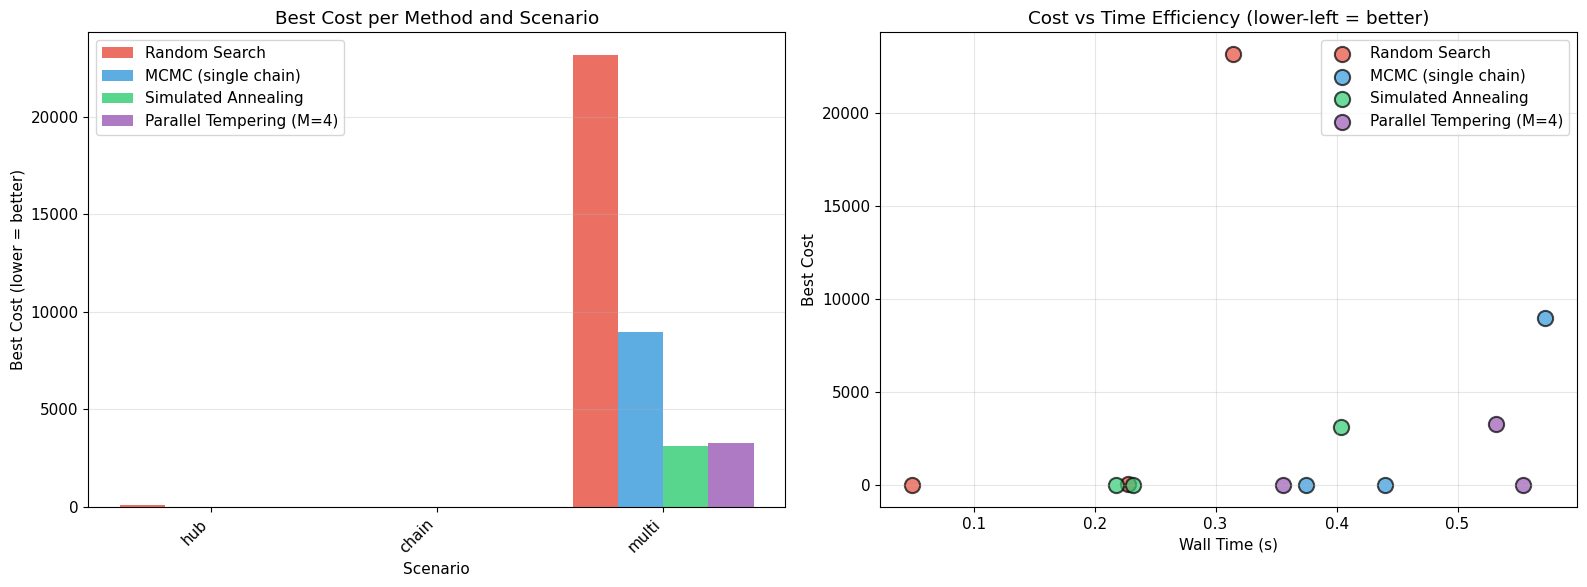

In [8]:
# Visualization: best cost per scenario
n_scenarios = len(comparison_results)
n_methods = len(METHODS)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Best cost comparison
x = np.arange(n_scenarios)
width = 0.2
colors = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']

for i, method in enumerate(comparison_results[0].methods):
    costs = [r.best_costs[i] for r in comparison_results]
    axes[0].bar(x + i * width, costs, width, label=method, color=colors[i % len(colors)], alpha=0.8)

axes[0].set_xlabel('Scenario')
axes[0].set_ylabel('Best Cost (lower = better)')
axes[0].set_title('Best Cost per Method and Scenario')
axes[0].set_xticks(x + width * (n_methods - 1) / 2)
axes[0].set_xticklabels([r.scenario_name.split('_')[0] for r in comparison_results], rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Plot 2: Time efficiency (cost vs time)
for i, method in enumerate(comparison_results[0].methods):
    times = [r.wall_times[i] for r in comparison_results]
    costs = [r.best_costs[i] for r in comparison_results]
    axes[1].scatter(times, costs, s=120, label=method, color=colors[i % len(colors)], alpha=0.7, edgecolors='black', linewidth=1.5)

axes[1].set_xlabel('Wall Time (s)')
axes[1].set_ylabel('Best Cost')
axes[1].set_title('Cost vs Time Efficiency (lower-left = better)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Statystyczne Porównanie

**Pytanie**: Czy różnice są statystycznie istotne?

**Analiza**:
- Który algorytm wygrywa najczęściej?
- Średni rank per metoda
- Speedup PT vs single-chain MCMC

In [9]:
# Compute rankings
rankings = {method: [] for method in comparison_results[0].methods}

for result in comparison_results:
    # Rank by best cost (1 = best)
    sorted_indices = np.argsort(result.best_costs)
    for rank, idx in enumerate(sorted_indices, start=1):
        method = result.methods[idx]
        rankings[method].append(rank)

print("Method Rankings (1 = best):")
print(f"\n{'Method':<25} {'Avg Rank':>10} {'Wins':>6} {'Best':>6} {'Worst':>6}")
print("-" * 60)

for method, ranks in rankings.items():
    avg_rank = np.mean(ranks)
    wins = sum(1 for r in ranks if r == 1)
    best = min(ranks)
    worst = max(ranks)
    print(f"{method:<25} {avg_rank:>10.2f} {wins:>6} {best:>6} {worst:>6}")

# Find MCMC and PT indices
method_names = comparison_results[0].methods
mcmc_idx = next((i for i, m in enumerate(method_names) if 'single chain' in m.lower()), None)
pt_idx = next((i for i, m in enumerate(method_names) if 'parallel' in m.lower()), None)

if mcmc_idx is not None and pt_idx is not None:
    print("\nPT vs MCMC (single chain):")
    speedups = []
    for result in comparison_results:
        mcmc_cost = result.best_costs[mcmc_idx]
        pt_cost = result.best_costs[pt_idx]
        if mcmc_cost > 0:
            improvement = (mcmc_cost - pt_cost) / mcmc_cost * 100
            speedups.append(improvement)
            print(f"  {result.scenario_name}: PT improves by {improvement:.1f}%")
    
    if speedups:
        print(f"\n  Average improvement: {np.mean(speedups):.1f}%")

Method Rankings (1 = best):

Method                      Avg Rank   Wins   Best  Worst
------------------------------------------------------------
Random Search                   3.33      0      2      4
MCMC (single chain)             3.00      0      2      4
Simulated Annealing             2.33      1      1      3
Parallel Tempering (M=4)        1.33      2      1      2

PT vs MCMC (single chain):
  hub_easy: PT improves by 0.0%
  chain_easy: PT improves by 0.0%
  multi_hub_mesh_easy: PT improves by 63.3%

  Average improvement: 21.1%


In [10]:
# Save results
output_dir = PROJECT_ROOT / "results" / "benchmark"
output_dir.mkdir(parents=True, exist_ok=True)

summary = {
    "mode": MODE,
    "seed": SEED,
    "budget": BUDGET,
    "comparisons": [
        {
            "scenario": r.scenario_name,
            "methods": r.methods,
            "best_costs": r.best_costs,
            "wall_times": r.wall_times,
            "n_evaluations": r.n_evaluations,
        }
        for r in comparison_results
    ],
    "rankings": {method: ranks for method, ranks in rankings.items()},
}

output_path = output_dir / f"comparison_{MODE}.json"
with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"\nResults saved to {output_path}")


Results saved to C:\Users\User\Zeszyt\pythonProject\mcmc_pesp\results\benchmark\comparison_quick.json
